In [1]:
import pandas as pd
import numpy as np

X = pd.read_csv("CICDDoS2019_LDAP_X.csv")
y = pd.read_csv("CICDDoS2019_LDAP_y.csv")

In [2]:
y = y.values.ravel()

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
X_train.head()

,Unnamed: 0,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Inbound
2062802,24886.0,17.0,1.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1160897,5547.0,17.0,1.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,...,944.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1845100,9845.0,17.0,1.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
548350,11109.0,17.0,0.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
540990,21571.0,17.0,1.0,2.0,0.0,2944.0,0.0,1472.0,1472.0,1472.0,...,8.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [5]:
X_train.shape

(1690587, 80)

In [6]:
X_test.shape

(422647, 80)

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Kelas 0: 4099
Kelas 1: 1686488


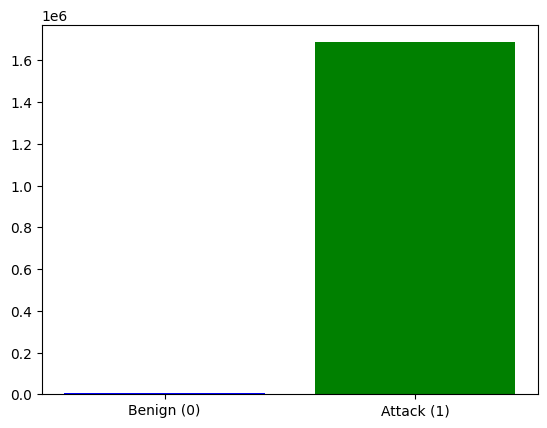

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Hitung nilai unik dan jumlahnya
labels, counts = np.unique(y_train, return_counts=True)

# Print hasilnya
for label, count in zip(labels, counts):
    print(f"Kelas {label}: {count}")

# Buat visualisasi manual pake bar plot
plt.bar(labels, counts, color=['blue', 'green'])
plt.xticks(labels, ['Benign (0)', 'Attack (1)'])
plt.show()

In [9]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

pca = PCA(n_components=0.98)
X_pca_train = pca.fit_transform(X_train_scaled) # Fit di Train
X_pca_test = pca.transform(X_test_scaled)     # Transform di Test
print("PCA Components :", X_pca_train.shape[1])

lda = LDA(solver='eigen', shrinkage='auto')
X_lda_train = lda.fit_transform(X_train_scaled, y_train.astype(int))
X_lda_test = lda.transform(X_test_scaled)
print("LDA Components :", X_lda_train.shape[1])

PCA Components : 28
LDA Components : 1


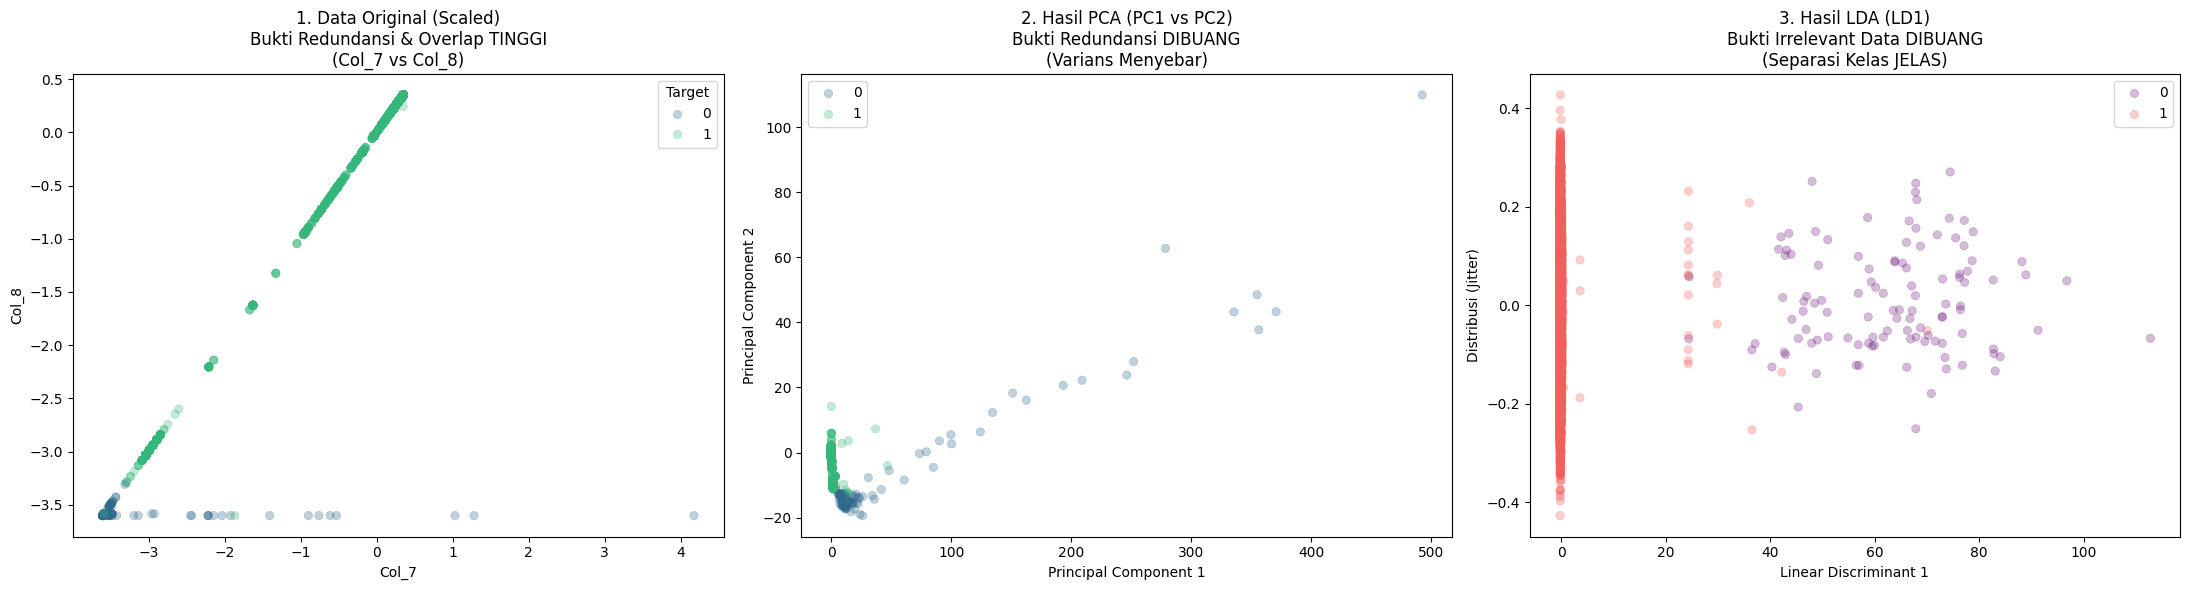

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Fungsi Utama buat Nampilin Perbandingan
def plot_pembuktian_reduksi(X_scaled, X_pca, X_lda, y, feature_names):
    # Ambil Sampling biar ringan (misal 10.000 data)
    sample_size = 50000
    indices = np.random.choice(len(X_scaled), sample_size, replace=False)
    
    # Siapin Data Sampling
    X_sc_s = X_scaled[indices]
    X_pca_s = X_pca[indices]
    X_lda_s = X_lda[indices]
    # Pastikan y_train berbentuk Series atau Array buat masking hue
    y_s = y.iloc[indices] if hasattr(y, 'iloc') else y[indices]

    # Buat Temporary DataFrame buat Data Original
    df_sc = pd.DataFrame(X_sc_s, columns=feature_names)
    df_sc['Target'] = y_s

    # Mulai Plotting (Subplot 1x3)
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))

    # --- PLOT 1: Bukti Masalah (Data Original) ---
    # Pilih 2 fitur yang paling redundan (ganti indeksnya sesuai dataset)
    col_a = feature_names[7] 
    col_b = feature_names[8] 
    
    sns.scatterplot(data=df_sc, x=col_a, y=col_b, hue='Target', 
                    palette='viridis', alpha=0.3, edgecolor=None, ax=axes[0])
    axes[0].set_title(f"1. Data Original (Scaled)\nBukti Redundansi & Overlap TINGGI\n({col_a} vs {col_b})")

    # --- PLOT 2: Bukti Solusi PCA ---
    # Plot PC1 vs PC2 (Maksimalisasi Varians)
    sns.scatterplot(x=X_pca_s[:, 0], y=X_pca_s[:, 1], hue=y_s, 
                    palette='viridis', alpha=0.3, edgecolor=None, ax=axes[1])
    axes[1].set_title("2. Hasil PCA (PC1 vs PC2)\nBukti Redundansi DIBUANG\n(Varians Menyebar)")
    axes[1].set_xlabel("Principal Component 1")
    axes[1].set_ylabel("Principal Component 2")

    # --- PLOT 3: Bukti Solusi LDA ---
    # Plot LD1 vs Random Noise (Maksimalisasi Separasi Kelas)
    # Kita flatten() LD1 biar jadi 1D, terus Y nya kasih jitter biar ga numpuk
    sns.scatterplot(x=X_lda_s.flatten(), y=np.random.normal(0, 0.1, size=len(X_lda_s)), 
                    hue=y_s, palette='magma', alpha=0.3, edgecolor=None, ax=axes[2])
    axes[2].set_title("3. Hasil LDA (LD1)\nBukti Irrelevant Data DIBUANG\n(Separasi Kelas JELAS)")
    axes[2].set_xlabel("Linear Discriminant 1")
    axes[2].set_ylabel("Distribusi (Jitter)")

    plt.tight_layout()
    plt.show()

column_names = df_original.columns.tolist() if 'df_original' in locals() else [f"Col_{i}" for i in range(X_train.shape[1])]

# 2. Cara Eksekusi (Contoh)
# Asumsi feature_names lo ambil dari dataframe original sebelum scaling
plot_pembuktian_reduksi(X_train_scaled, X_pca_train, X_lda_train, y_train, column_names)

In [23]:
import time
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras import Input
from sklearn.utils import class_weight
from sklearn.metrics import confusion_matrix
import psutil
import os
import gc

# Hitung bobot otomatis
# y_train adalah data asli yang masih imbalance (1,6 juta itu)
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

dict_weights = {i: weights[i] for i in range(len(weights))}
print(f"Bobot yang akan diterapkan: {dict_weights}")

def get_memory_usage():
    # Menghitung penggunaan memori oleh proses saat ini dalam MB
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

def evaluate_lstm_variant(X_train_data, y_train_data, X_test_data, y_test_data, name, batch_size):
    n_features = X_train_data.shape[1]
    
    # Reshape tetap sama
    X_t_res = np.reshape(X_train_data, (X_train_data.shape[0], 1, n_features))
    X_v_res = np.reshape(X_test_data, (X_test_data.shape[0], 1, n_features))
    
    # Build Model (Versi Keras 3 - No Warning)
    model = Sequential([
        # Pakai Input object di paling atas
        Input(shape=(1, n_features)), 
        LSTM(64, activation='tanh'),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    # Early Stopping
    es = EarlyStopping(monitor='val_loss', mode='min', verbose=0, patience=3, restore_best_weights=True)

    gc.collect() # Bersihin RAM manual sebelum mulai
    mem_before = get_memory_usage()
    
    # Training
    print(f"Training {name} with {n_features} features...")
    start_train = time.time()
    history = model.fit(X_t_res, y_train_data, class_weight=dict_weights, epochs=10, batch_size=batch_size, 
              validation_data=(X_v_res, y_test_data), callbacks=[es], verbose=1)
    end_train = time.time()

    final_loss = history.history['loss'][-1]
    final_val_loss = history.history['val_loss'][-1]
    
    # Inference
    start_inf = time.time()
    y_pred = model.predict(X_v_res)
    end_inf = time.time()

    gc.collect() # Bersihin lagi setelah kelar
    mem_after = get_memory_usage()
    mem_consumed = mem_after - mem_before
    
    y_pred_bin = (y_pred > 0.5).astype(int)
    acc = accuracy_score(y_test_data, y_pred_bin)
    prec = precision_score(y_test_data, y_pred_bin, average='macro')
    rec = recall_score(y_test_data, y_pred_bin, average='macro')
    f1 = f1_score(y_test_data, y_pred_bin, average='macro')

    cm = confusion_matrix(y_test_data, y_pred_bin)

    # 1. Pastikan lo udah dapet hasil prediksi (y_pred)
    # X_test_reduced adalah data test hasil PCA/LDA lo
    X_test_reshaped = np.reshape(X_test_data, (X_test_data.shape[0], 1, X_test_data.shape[1]))
    y_pred_probs = model.predict(X_test_reshaped)
    
    # 2. Konversi probabilitas ke biner (0 atau 1)
    y_pred_classes = (y_pred_probs > 0.5).astype(int).flatten()
    
    # 3. Buat DataFrame untuk record
    df_record = pd.DataFrame({
        'Actual_Label': y_test.values if hasattr(y_test, 'values') else y_test,
        'Predicted_Label': y_pred_classes,
        'Confidence_Score': y_pred_probs.flatten() # Nilai probabilitas (0-1)
    })
    
    # 4. Tambahin kolom status buat nandain mana yang salah tebak
    df_record['Status'] = np.where(df_record['Actual_Label'] == df_record['Predicted_Label'], 'Correct', 'Wrong')
    
    # 5. Simpan ke CSV
    filename = name
    df_record.to_csv(filename, index=False)
    
    print(f"Hasil record berhasil disimpan ke {filename}")
    
    return {
        'Metode': name,
        'Train Loss': final_loss,
        'Val Loss': final_val_loss,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'cm': cm,
        'Inf Time (s)': end_inf - start_inf,
        'Train Time (s)': end_train - start_train,
        'Memory Usage (MB)': mem_consumed
    }

Bobot yang akan diterapkan: {0: np.float64(206.21944376677237), 1: np.float64(0.5012152473068293)}


In [24]:
results = []

results.append(evaluate_lstm_variant(X_train_scaled, y_train, X_test_scaled, y_test, "Original", 128))

Training Original with 80 features...
Epoch 1/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.9991 - loss: 0.0103 - val_accuracy: 0.9996 - val_loss: 0.0019
Epoch 2/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.9997 - loss: 0.0070 - val_accuracy: 0.9999 - val_loss: 7.1230e-04
Epoch 3/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.9997 - loss: 0.0083 - val_accuracy: 0.9999 - val_loss: 8.3562e-04
Epoch 4/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.9999 - loss: 0.0070 - val_accuracy: 0.9999 - val_loss: 5.9204e-04
Epoch 5/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.9999 - loss: 0.0070 - val_accuracy: 0.9999 - val_loss: 0.0021
Epoch 6/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 39s 3ms/step - accuracy: 0.9999 - loss: 0.0050 - val_accuracy: 0.9999 - val_loss: 7.0896e-04
Epoch 7/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.9998 - loss: 0.0058 - val_accuracy: 0.9999 - val_loss: 5.5321e-04
Epoch 8/10


In [25]:
results.append(evaluate_lstm_variant(X_pca_train, y_train, X_pca_test, y_test, "PCA (30 PC)", 128))

Training PCA (30 PC) with 30 features...
Epoch 1/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.9990 - loss: 0.0145 - val_accuracy: 0.9998 - val_loss: 0.0022
Epoch 2/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.9996 - loss: 0.0059 - val_accuracy: 0.9997 - val_loss: 0.0018
Epoch 3/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.9995 - loss: 0.0071 - val_accuracy: 0.9998 - val_loss: 9.1304e-04
Epoch 4/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.9997 - loss: 0.0046 - val_accuracy: 0.9999 - val_loss: 0.0010
Epoch 5/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step - accuracy: 0.9997 - loss: 0.0041 - val_accuracy: 0.9999 - val_loss: 6.0149e-04
Epoch 6/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.9998 - loss: 0.0047 - val_accuracy: 0.9999 - val_loss: 7.3527e-04
Epoch 7/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - accuracy: 0.9998 - loss: 0.0048 - val_accuracy: 0.9999 - val_loss: 5.1434e-04
Epoch 8/10
1

In [26]:
results.append(evaluate_lstm_variant(X_lda_train, y_train, X_lda_test, y_test, "LDA (1 PC)", 128))

Training LDA (1 PC) with 1 features...
Epoch 1/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.9996 - loss: 0.0163 - val_accuracy: 0.9996 - val_loss: 0.0035
Epoch 2/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.9996 - loss: 0.0106 - val_accuracy: 0.9996 - val_loss: 0.0028
Epoch 3/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.9995 - loss: 0.0107 - val_accuracy: 0.9996 - val_loss: 0.0023
Epoch 4/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.9996 - loss: 0.0109 - val_accuracy: 0.9996 - val_loss: 0.0043
Epoch 5/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 41s 3ms/step - accuracy: 0.9996 - loss: 0.0092 - val_accuracy: 0.9996 - val_loss: 0.0023
Epoch 6/10
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 40s 3ms/step - accuracy: 0.9996 - loss: 0.0114 - val_accuracy: 0.9996 - val_loss: 0.0029
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step
13208/13208 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step
Hasil record berhasil disimpan ke LDA (1 PC)


In [27]:
# Tampilkan Hasil dalam Tabel
df_final = pd.DataFrame(results)
print("\n--- HASIL EVALUASI KOMPREHENSIF ---")
print(df_final.to_string(index=False))


--- HASIL EVALUASI KOMPREHENSIF ---
     Metode  Train Loss  Val Loss  Accuracy  Precision   Recall  F1-Score                         cm  Inf Time (s)  Train Time (s)  Memory Usage (MB)
   Original    0.006322  0.000493  0.999917   0.983491 0.999958  0.991586  [[1025, 0], [35, 421587]]     20.476879      405.090740        -502.343750
PCA (30 PC)    0.006558  0.000689  0.999917   0.984373 0.998985  0.991570  [[1023, 2], [33, 421589]]     18.262084      428.833822         -34.546875
 LDA (1 PC)    0.011371  0.002869  0.999600   0.929529 0.999313  0.961785 [[1024, 1], [168, 421454]]     17.418407      244.442398          42.148438


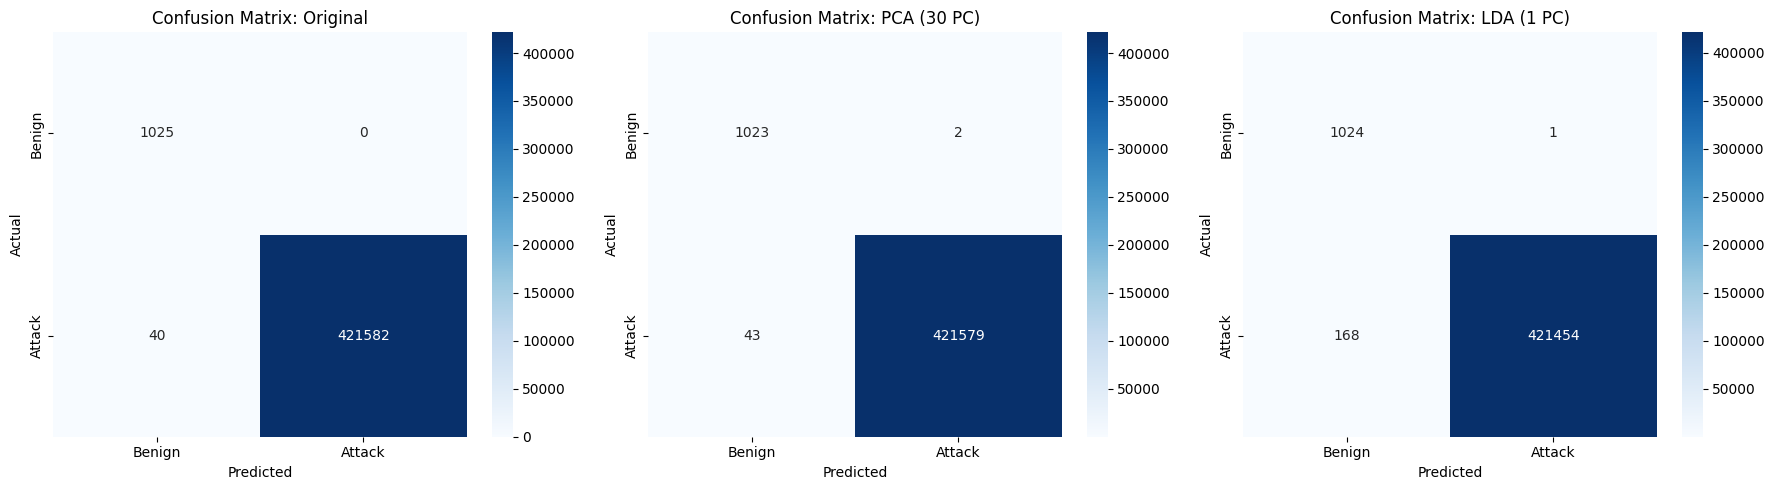

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, res in enumerate(results):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Benign', 'Attack'], yticklabels=['Benign', 'Attack'])
    axes[i].set_title(f"Confusion Matrix: {res['Metode']}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()

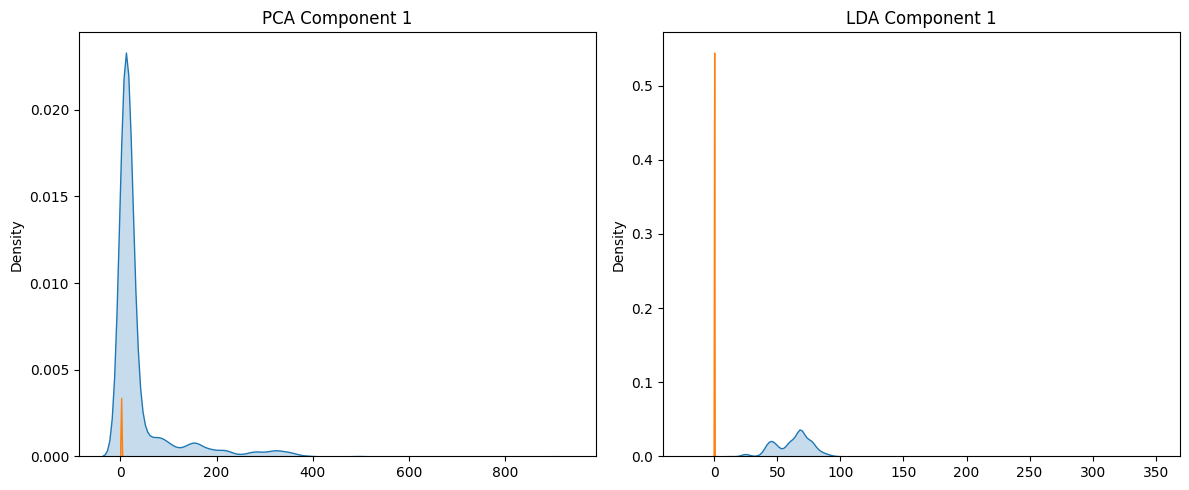

In [19]:
plt.figure(figsize=(12, 5))

# PCA Density Plot
plt.subplot(1, 2, 1)
for label in np.unique(y_train):
    sns.kdeplot(X_pca_train[y_train==label, 0], label=f'Class {label}', fill=True)
plt.title("PCA Component 1")

# LDA Density Plot
plt.subplot(1, 2, 2)
for label in np.unique(y_train):
    sns.kdeplot(X_lda_train[y_train==label, 0], label=f'Class {label}', fill=True)
plt.title("LDA Component 1")

plt.tight_layout()
plt.show()

In [20]:
cm_list = []
for res in results:
    cm = res['cm']
    cm_data = {
        'Metode': res['Metode'],
        'True_Benign (TN)': cm[0, 0],
        'False_Attack (FP)': cm[0, 1],
        'False_Benign (FN)': cm[1, 0],
        'True_Attack (TP)': cm[1, 1]
    }
    cm_list.append(cm_data)

df_cm = pd.DataFrame(cm_list)

# Ekspor ke CSV
df_cm.to_csv('hasil_confusion_matrix_perbandingan.csv', index=False)
print("File 'hasil_confusion_matrix_perbandingan.csv' berhasil disimpan!")

File 'hasil_confusion_matrix_perbandingan.csv' berhasil disimpan!
